# EDA on Retail Sales Data
**Oasis Infobyte SIP | Data Analytics | Level 1, Task 1**  
**Author:** Nimisha S

**Objective:** Explore retail transactions to find sales trends, customer demographics and category performance, and recommend business actions.  
**Dataset:** Retail Sales Dataset (Kaggle, mohammadtalib786), 1,000 transactions, 9 columns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [2]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nNull values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (1000, 9)

Data types:
 Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

Null values:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


In [3]:
df["Date"] = pd.to_datetime(df["Date"])

num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

stats = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T
stats["mode"] = [df[c].mode()[0] for c in num_cols]
stats

,mean,median,std,min,max,mode
Age,41.392,42.0,13.681430,18.0,64.0,43
Quantity,2.514,3.0,1.132734,1.0,4.0,4
Price per Unit,179.890,50.0,189.681356,25.0,500.0,50
Total Amount,456.000,135.0,559.997632,25.0,2000.0,50


**Observations**
- Average customer age is about 41 (range 18 to 64), so the customer base is mostly working-age adults.
- Total Amount has a mean of 456 but a median of only 135, so the data is right-skewed. A smaller number of high-value purchases pulls the average up.
- Price per Unit has a median of 50 against a mean of about 180, so most items are low-priced, with a few expensive items at 300 and 500.

**Note:** Two transactions are dated 1 Jan 2024. They are excluded from the time-series and later analysis so that all results cover calendar year 2023 (998 transactions).

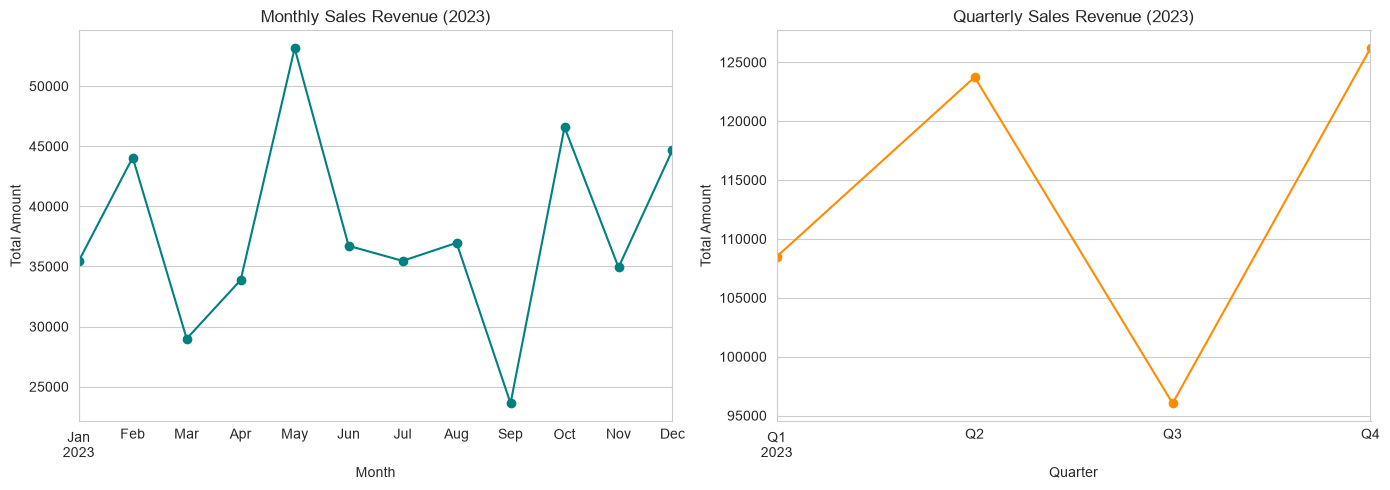

Best month: 2023-05 53150
Weakest month: 2023-09 23620


In [4]:
df = df[df["Date"] < "2024-01-01"].copy()   # remove the lone 2024 day

df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

monthly = df.groupby("Month")["Total Amount"].sum()
quarterly = df.groupby("Quarter")["Total Amount"].sum()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

monthly.plot(kind="line", marker="o", ax=ax[0], color="teal")
ax[0].set_title("Monthly Sales Revenue (2023)")
ax[0].set_ylabel("Total Amount")
ax[0].set_xlabel("Month")

quarterly.plot(kind="line", marker="o", ax=ax[1], color="darkorange")
ax[1].set_title("Quarterly Sales Revenue (2023)")
ax[1].set_ylabel("Total Amount")
ax[1].set_xlabel("Quarter")

plt.tight_layout()
plt.show()

print("Best month:", monthly.idxmax(), monthly.max())
print("Weakest month:", monthly.idxmin(), monthly.min())

**Observations**
- May was the best month (53,150) and September was the weakest (23,620). That is a very large gap.
- Monthly sales are volatile. There is no steady growth, and sales swing up and down from month to month.
- Quarterly view: Q2 (about 124k) and Q4 (about 126k) are the strongest quarters. Q3 is the lowest (about 96k).
- Recommendation: plan stock and promotions ahead of the Q3 dip, and repeat the campaigns that worked in May, October and December.

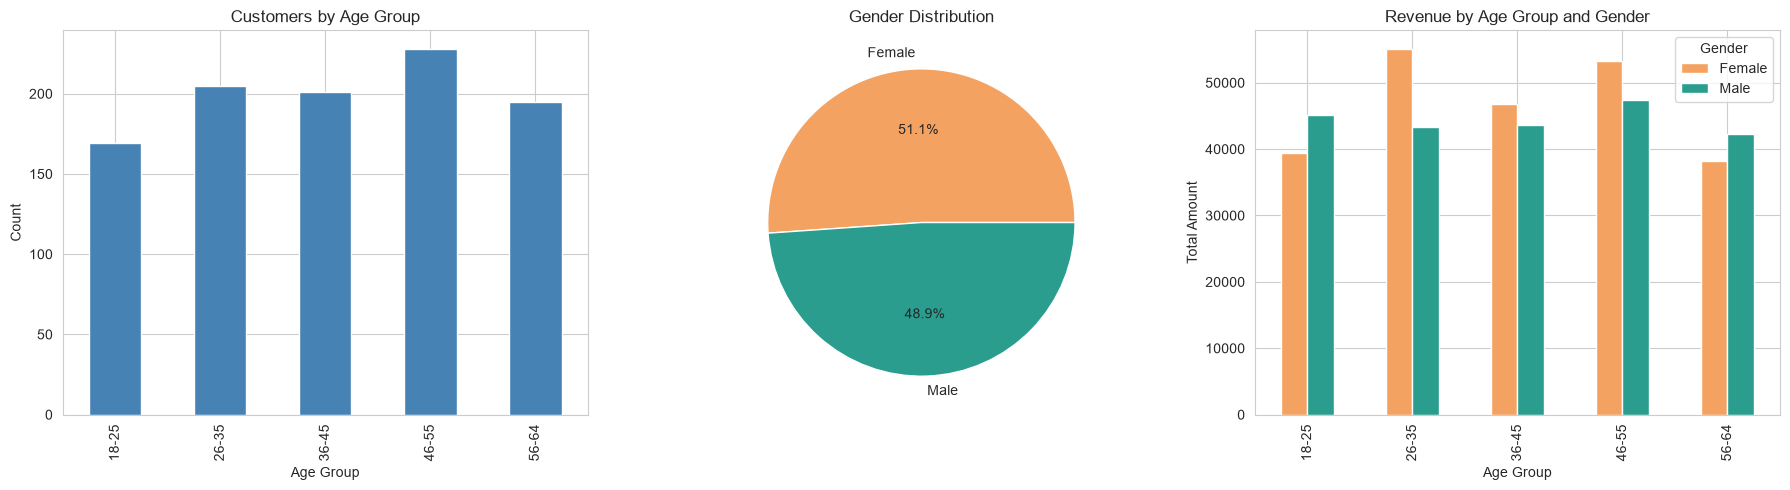

        count     sum        mean
Gender                           
Female    510  232840  456.549020
Male      488  221630  454.159836


In [5]:
# Age groups
bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-64"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Customers per age group
df["Age Group"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Customers by Age Group")
ax[0].set_ylabel("Count")

# 2. Gender split
df["Gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax[1],
                                 colors=["#f4a261", "#2a9d8f"])
ax[1].set_title("Gender Distribution")
ax[1].set_ylabel("")

# 3. Revenue by age group and gender
rev = df.groupby(["Age Group", "Gender"], observed=True)["Total Amount"].sum().unstack()
rev.plot(kind="bar", ax=ax[2], color=["#f4a261", "#2a9d8f"])
ax[2].set_title("Revenue by Age Group and Gender")
ax[2].set_ylabel("Total Amount")

plt.tight_layout()
plt.show()

print(df.groupby("Gender")["Total Amount"].agg(["count", "sum", "mean"]))

**Observations**
- Gender split is nearly even: 51.1% female and 48.9% male. Average spend per transaction is almost the same (about 456 vs 454), so gender does not change spending per purchase.
- Women generate more total revenue (232,840 vs 221,630), mainly in the 26-35 and 46-55 age groups.
- Men lead in the 18-25 and 56-64 groups.
- The 46-55 group has the most customers, and 18-25 has the fewest.

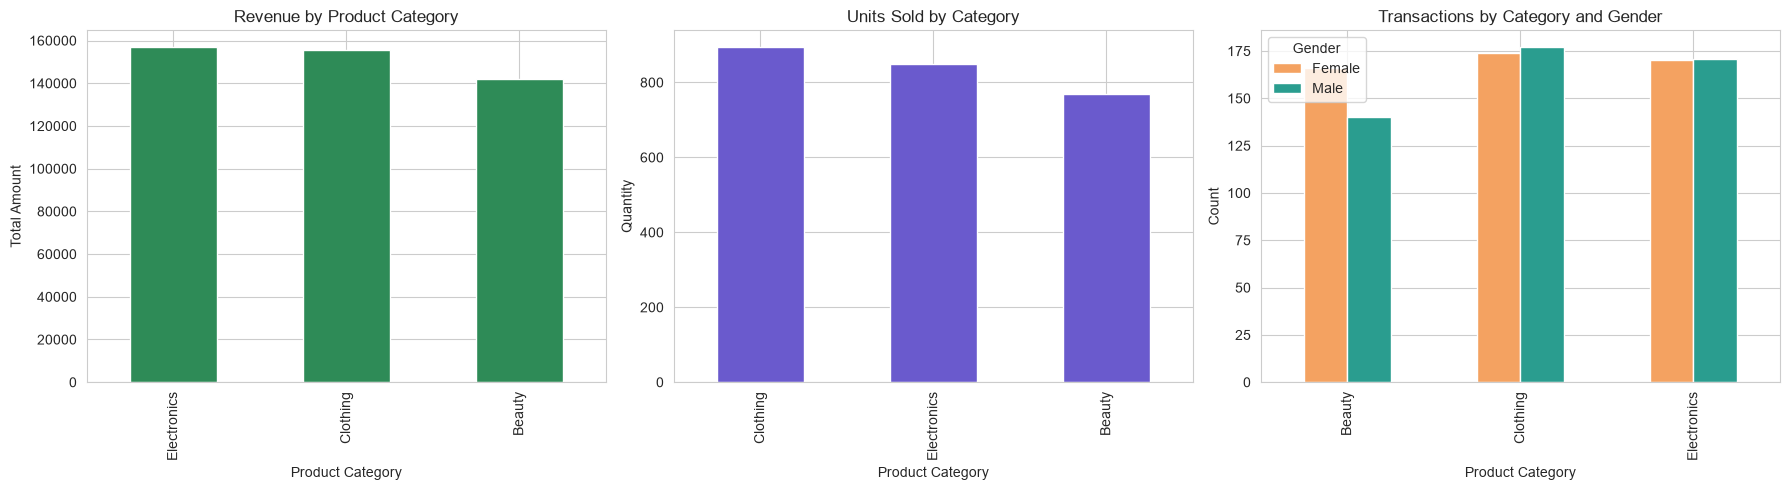

Product Category  Age Group
Clothing          26-35        39975
Electronics       46-55        35455
Beauty            46-55        34720
Electronics       36-45        33915
                  56-64        33480
Beauty            18-25        31280
                  26-35        31240
Clothing          46-55        30485
                  36-45        29550
                  56-64        29060
Name: Total Amount, dtype: int64


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Revenue by category
cat_rev = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
cat_rev.plot(kind="bar", ax=ax[0], color="seagreen")
ax[0].set_title("Revenue by Product Category")
ax[0].set_ylabel("Total Amount")

# 2. Units sold by category
qty = df.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False)
qty.plot(kind="bar", ax=ax[1], color="slateblue")
ax[1].set_title("Units Sold by Category")
ax[1].set_ylabel("Quantity")

# 3. Category by gender
pd.crosstab(df["Product Category"], df["Gender"]).plot(
    kind="bar", ax=ax[2], color=["#f4a261", "#2a9d8f"])
ax[2].set_title("Transactions by Category and Gender")
ax[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

# Top 10 best-selling combinations (this dataset has no product names)
top10 = (df.groupby(["Product Category", "Age Group"], observed=True)["Total Amount"]
           .sum().sort_values(ascending=False).head(10))
print(top10)

**Note:** This dataset has only 3 product categories and no product names, so a "top 10 products" list is not possible. I show the top 10 Category x Age Group combinations by revenue instead.

**Observations**
- Electronics earns the most revenue (about 157k), followed closely by Clothing (about 155k). Beauty is lowest (about 141k).
- Clothing sells the most units (about 890), but Electronics earns more revenue. This means Electronics sells fewer items at a higher price, while Clothing wins on volume.
- Beauty is bought more by women, while Clothing and Electronics are balanced between men and women.
- The best-performing segment is Clothing for ages 26-35 (39,975), followed by Electronics for ages 46-55 (35,455) and Beauty for ages 46-55 (34,720).
- The 46-55 group appears three times in the top 10, so it is a high-value age group.

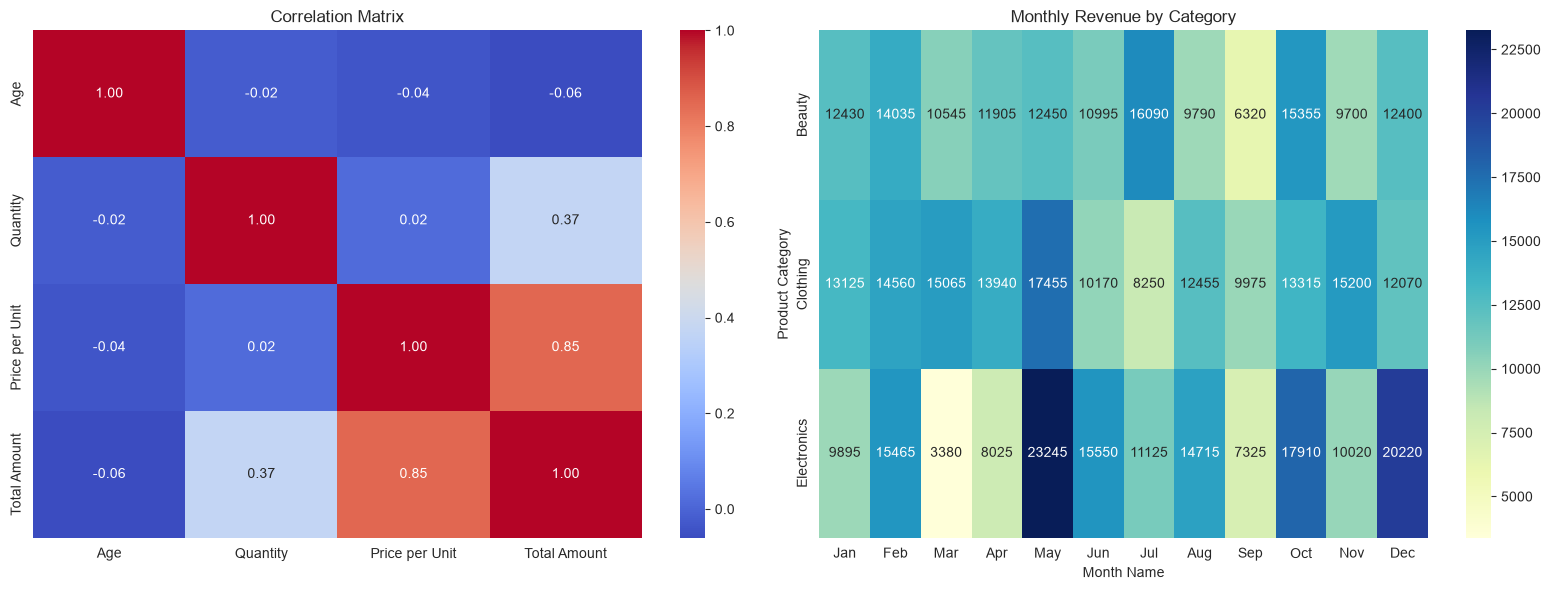

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# 1. Correlation heatmap
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=ax[0])
ax[0].set_title("Correlation Matrix")

# 2. Extra insight: monthly revenue by category
df["Month Name"] = df["Date"].dt.strftime("%b")
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
pivot = df.pivot_table(values="Total Amount", index="Product Category",
                       columns="Month Name", aggfunc="sum")[month_order]
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax[1])
ax[1].set_title("Monthly Revenue by Category")

plt.tight_layout()
plt.show()

**Observations: Correlation**
- Price per Unit has a strong positive correlation with Total Amount (0.85). Quantity has a moderate one (0.37). Revenue is driven mostly by how expensive the items are, not by how many are bought.
- Age has almost no correlation with any variable (between -0.06 and -0.02), so customer age does not predict spending or quantity.

**Observations: Monthly revenue by category (extra insight)**
- Electronics is the most volatile category. It peaks at 23,245 in May and drops to 3,380 in March. This explains the May peak in the overall sales trend.
- September is weak in all three categories (Beauty 6,320, Electronics 7,325, Clothing 9,975), which explains the overall September low.
- Clothing is the most stable category. Its low is in July (8,250) and it peaks in May (17,455).
- Beauty is strongest in July (16,090) and October (15,355).
- December and October are strong for Electronics, which fits the festive and year-end shopping period.

## Conclusion

The analysis covers 998 transactions from 2023 across 3 product categories. The data was clean, with no nulls or duplicates. Revenue is split almost evenly between the categories and between genders, but sales are highly seasonal, and price per unit matters more than quantity.

### Recommendations
1. **Plan for the Q3 slump.** July to September is the weakest period, and September is low in every category. Run discounts, bundles or loyalty campaigns in this window, and keep stock levels lower to avoid dead inventory.
2. **Build Electronics campaigns around May, October and December.** These are its peak months. Also investigate the March slump (3,380), since it may be a stock, pricing or marketing gap that can be fixed.
3. **Target by age group.** Clothing performs best with ages 26-35, and Electronics and Beauty perform best with ages 46-55. Focus advertising and product ranges on these groups.
4. **Raise order value through premium items and upselling.** Because price per unit drives revenue (r = 0.85), bundles and premium product placement should raise revenue more than pushing for higher quantities.
5. **Run gender-focused campaigns for Beauty.** Women buy more Beauty products, while Clothing and Electronics appeal equally to both genders.